In [1]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester

In [2]:
# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=250)


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 92,133 bars (250 tick)


TickData(250 tick bars, n_bars=92,133, from 2026-02-01 23:00:00.003520-06:00 to 2026-03-02 07:30:20.001880-06:00)

In [3]:
# ES contract specs
tick_value = 12.50        # $12.50 per tick (0.25 pts)
contract_multiplier = 50  # $50 per point
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)

print(f'Bars: {n_bars:,}')
print(f'Timeframe: {timeframe}')
print(f'Date range: {indices[0]} to {indices[-1]}')

Bars: 92,133
Timeframe: 1min
Date range: 2026-02-01 23:00:00.003520-06:00 to 2026-03-02 07:30:20.001880-06:00


In [4]:
# Look-ahead "cheat" strategy:
# - When flat, peek 20 bars into the future
# - If price will be higher → go long, if lower → go short
# - TP = 10 ticks, SL = 10 ticks (1:1 RR)

tp_ticks = 10
sl_ticks = 10
tp_points = tp_ticks * 0.25  # 2.5 points
sl_points = sl_ticks * 0.25  # 2.5 points

lookahead = 20

signal = np.zeros(n_bars)
position = 0
entry_price = 0.0

for i in range(n_bars):
    close = ohlc[i, 3]
    high = ohlc[i, 1]
    low = ohlc[i, 2]

    if position != 0:
        hit_tp = False
        hit_sl = False

        if position == 1:
            hit_tp = high >= entry_price + tp_points
            hit_sl = low <= entry_price - sl_points
        else:
            hit_tp = low <= entry_price - tp_points
            hit_sl = high >= entry_price + sl_points

        if hit_tp or hit_sl:
            position = 0
    else:
        # Look ahead 20 bars — if we can see the future, use it
        future_idx = i + lookahead
        if future_idx < n_bars:
            future_close = ohlc[future_idx, 3]
            if future_close > close:
                position = 1
            elif future_close < close:
                position = -1
            entry_price = close

    signal[i] = position

print(f'Total entries: {int(np.sum(np.abs(np.diff(signal)) > 0))}')
print(f'Long entries: {int(np.sum(np.diff(signal) > 0))}')
print(f'Short entries: {int(np.sum(np.diff(signal) < 0))}')

Total entries: 24537
Long entries: 12269
Short entries: 12268


In [5]:
# Run backtester — no slippage, $5 round trip commission
bt = Backtester(
    ohlc=ohlc,
    indicies=indices,
    signal=signal,
    timeframe=timeframe,
    tick_value=tick_value,
    contract_multiplier=contract_multiplier,
    initial_equity=initial_equity,
    slippage_ticks=0,
    commission=5.0,
)
bt.full_backtest()
print(bt)


        Backtest Results from 2026-02-01 23:00:00.003520-06:00 to 2026-03-02 07:30:20.001880-06:00 (28 days 08:30:19.998360)
        Equity:     $100,000.00 -> $722,292.50
        Buy & Hold: $100,000.00 -> $93,162.50
        Buy & Hold Return (%): -6.84%
        Strategy Return (%):   622.29%

        Total Trades:     12269.00
        Win Rate:         71.88%
        95% CI:           71.08% - 72.67%
        Avg. Win:         $115.07
        Avg. Loss:        $-113.78
        Ratio Win/Loss:   1.01
        Expected Value:   $50.72

        Largest Win:      $2,882.50
        Largest Loss:     $-442.50
        Max Consec. Wins: 31
        Max Consec. Loss: 6

        Max Drawdown from 2026-02-16 15:34:46.007450-06:00 to 2026-02-17 00:24:23.006490-06:00 (0 days 08:49:36.999040)
        Max Drawdown:     $-1,525.00
        Max Drawdown (%): -0.33%

        Slippage:   0 ticks
        Commission: $5.00
        Contract Multiplier: $50.00
        Transaction Costs:   $61,345.00

        

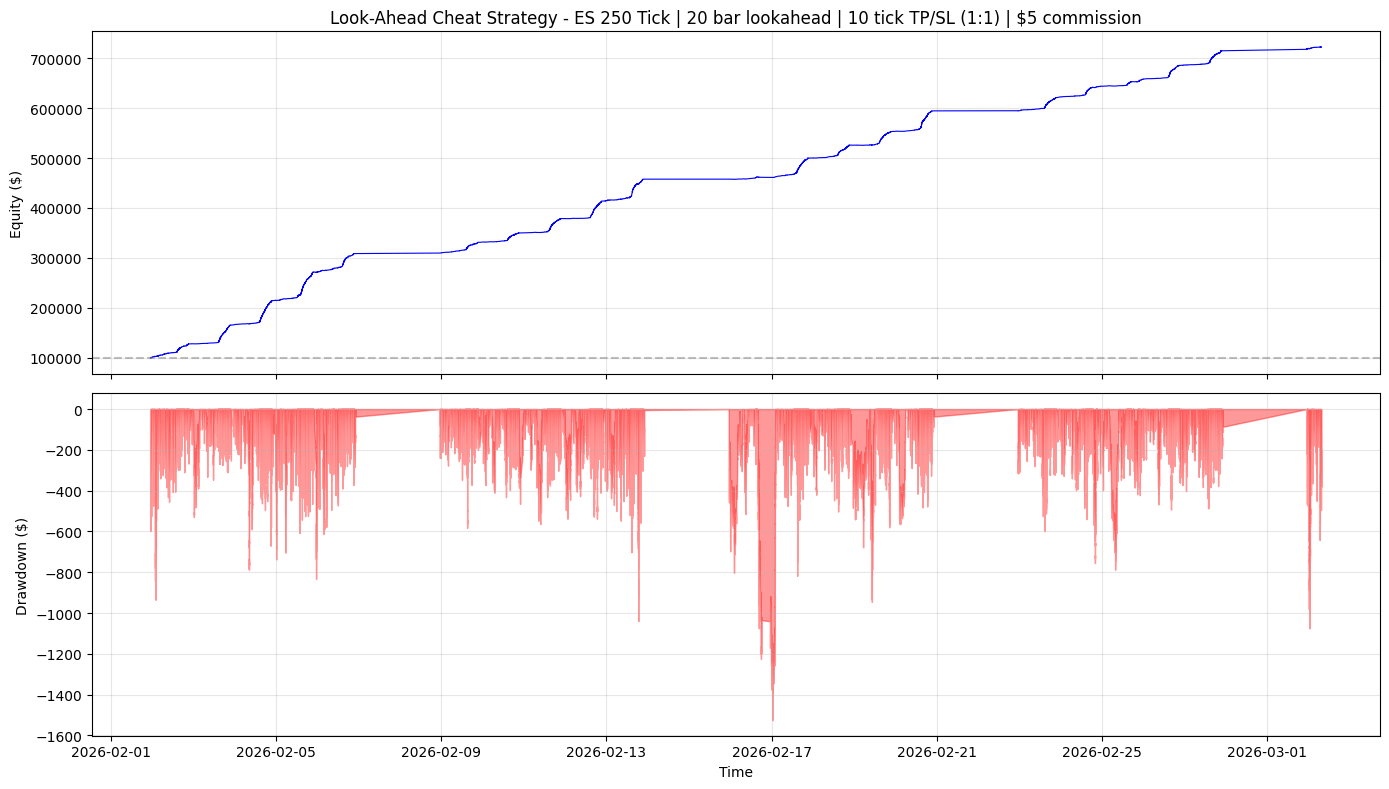

In [6]:
# Equity curve plot
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

ax1.plot(indices, bt.equity_curve, linewidth=0.8, color='blue')
ax1.axhline(initial_equity, color='gray', linestyle='--', alpha=0.5)
ax1.set_ylabel('Equity ($)')
ax1.set_title('Look-Ahead Cheat Strategy - ES 250 Tick | 20 bar lookahead | 10 tick TP/SL (1:1) | $5 commission')
ax1.grid(True, alpha=0.3)

ax2.fill_between(indices, bt.drawdown_curve, 0, color='red', alpha=0.4)
ax2.set_ylabel('Drawdown ($)')
ax2.set_xlabel('Time')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Generate interactive HTML report
from Engine.Report import generate_report

generate_report(bt, 'backtest_report.html', open_browser=True)

Report saved: /Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html


'/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/backtest_report.html'